<a href="https://colab.research.google.com/github/miasmita/DM_ACT_2.10_DP/blob/main/Actividad_2_10_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 2.10 de Clustering: K-means y Jerárquico
**Asignatura:** Minería de Datos

**Nombre:** Daniel Pellegrini


In [27]:
# Importación de librerías base
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

# Librerías de Machine Learning (Scikit-Learn y SciPy)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## EJERCICIO 1: K-means (Segmentación de clientes)
### Fase 1: Hipótesis antes de calcular

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.


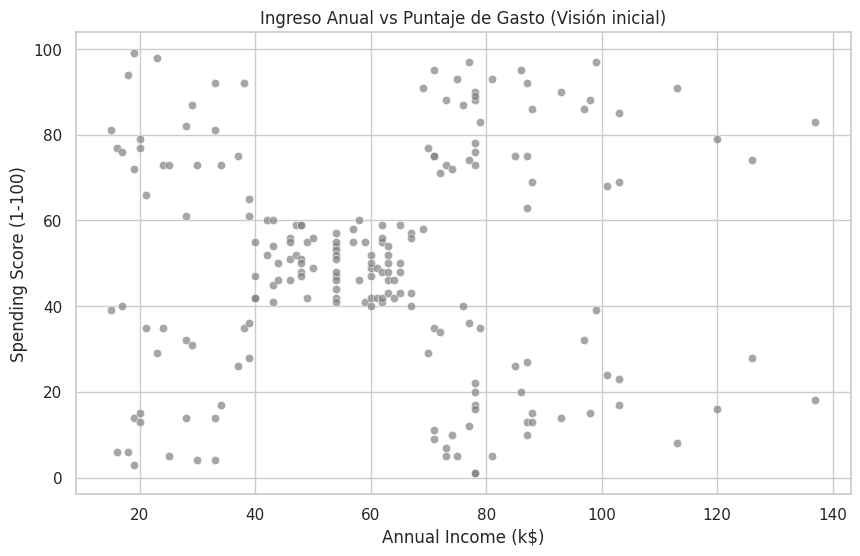

In [15]:
# 1. Cargar el dataset usando kagglehub
path_ej1 = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
csv_path_ej1 = os.path.join(path_ej1, "Mall_Customers.csv")

df_mall = pd.read_csv(csv_path_ej1)

# Gráfico de dispersión inicial (sin colorear)
sns.scatterplot(data=df_mall, x='Annual Income (k$)', y='Spending Score (1-100)', color='gray', alpha=0.7)
plt.title("Ingreso Anual vs Puntaje de Gasto (Visión inicial)")
plt.show()

**Hipótesis inicial:**
Al observar la nube de puntos, distingo visualmente **5 grupos principales**: un grupo central bastante denso y cuatro grupos ubicados en las esquinas (altos ingresos/alto gasto, altos ingresos/bajo gasto, bajos ingresos/alto gasto y bajos ingresos/bajo gasto).

### Fase 2: Cargar y explorar

Dimensiones: (200, 5)

Tipos de dato y nulos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Estadísticos descriptivos:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


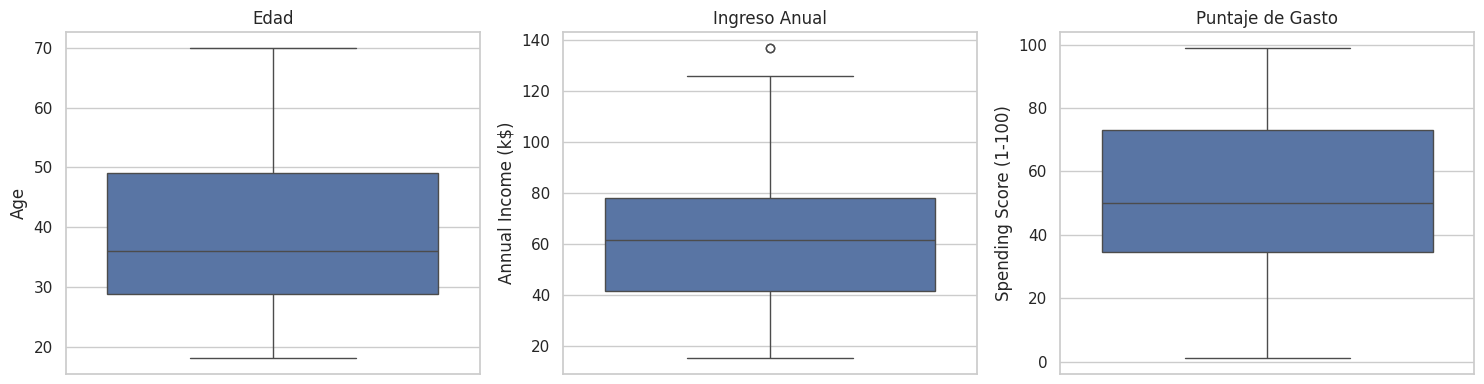

In [16]:
# Exploración inicial
print("Dimensiones:", df_mall.shape)
print("\nTipos de dato y nulos:")
df_mall.info()

print("\nEstadísticos descriptivos:")
display(df_mall.describe())

# Distribuciones y atípicos
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df_mall['Age'], ax=axes[0]).set_title('Edad')
sns.boxplot(y=df_mall['Annual Income (k$)'], ax=axes[1]).set_title('Ingreso Anual')
sns.boxplot(y=df_mall['Spending Score (1-100)'], ax=axes[2]).set_title('Puntaje de Gasto')
plt.tight_layout()
plt.show()

**Decisiones de exploración:**
*   **CustomerID:** Es un identificador correlativo sin valor analítico. Se excluye porque distorsionaría el cálculo de distancias.
*   **Gender:** Es una variable categórica. Si se incluye en un cálculo de distancia euclidiana (codificada como 0/1), su magnitud discreta forzará agrupamientos artificiales. K-means asume espacios continuos, por lo que la dejaremos fuera para este análisis geométrico.

### Fase 3: Preparar: variables y escala

In [17]:
# Selección de variables continuas
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df_mall[features]

print("Rangos antes de escalar (Min y Max):")
display(X.agg(['min', 'max']))

# Estandarización
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns)

Rangos antes de escalar (Min y Max):


,Annual Income (k$),Spending Score (1-100)
min,15,1
max,137,99


**Decisión sobre estandarizar:**
Aunque los rangos numéricos de ambas variables son casualmente similares (15-137 para ingresos, 1-99 para puntaje), representan unidades totalmente distintas (miles de dólares vs puntos de índice). Estandarizaremos para asegurar que la varianza de ninguna variable domine el modelo por defecto.

### Fase 4: Ajustar K-means y explorar k

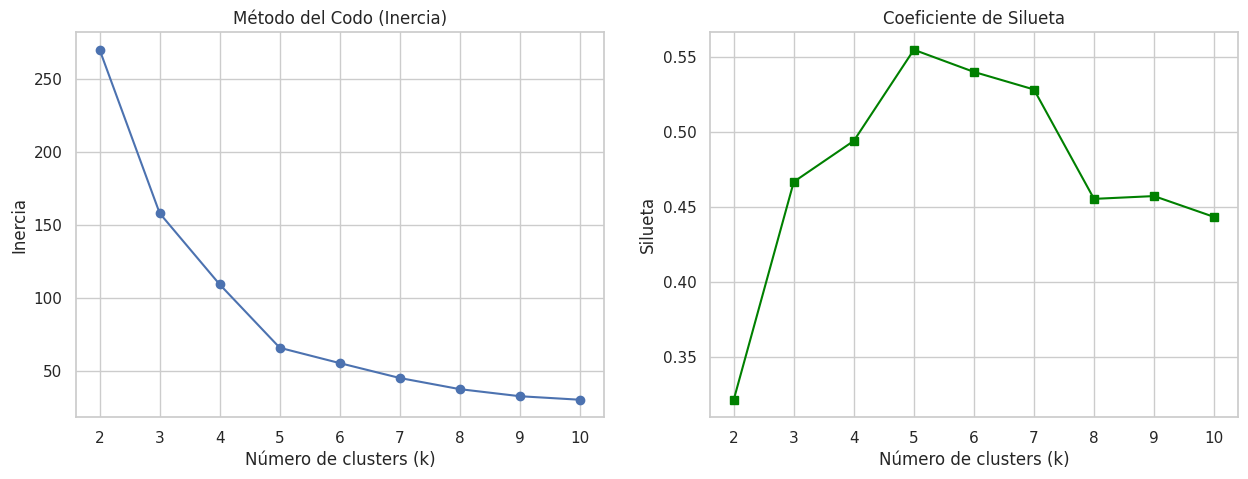

In [18]:
inertias = []
silhouettes = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, kmeans.labels_))

# Gráficos
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Curva de Inercia
axes[0].plot(K_range, inertias, marker='o')
axes[0].set_title('Método del Codo (Inercia)')
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Inercia')

# Curva de Silueta
axes[1].plot(K_range, silhouettes, marker='s', color='green')
axes[1].set_title('Coeficiente de Silueta')
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Silueta')

plt.show()

**Sobre la inercia:**
La inercia siempre disminuye al aumentar `k` porque al haber más centroides, la distancia promedio de cada punto a su centroide más cercano se reduce matemáticamente (si k = n, inercia = 0). Por eso no buscamos el mínimo, sino el "codo" donde la caída pierde fuerza.

### Fase 5: Evaluar con más de una evidencia

In [19]:
k_opt = 5 # Elegido por codo y silueta

# Mini-experimento: Estandarizado vs Sin Estandarizar
kmeans_scaled = KMeans(n_clusters=k_opt, n_init=10, random_state=42)
labels_scaled = kmeans_scaled.fit_predict(X_scaled)

kmeans_unscaled = KMeans(n_clusters=k_opt, n_init=10, random_state=42)
labels_unscaled = kmeans_unscaled.fit_predict(X)

print("Tabla de contingencia (Estandarizado vs Sin estandarizar):")
display(pd.crosstab(labels_scaled, labels_unscaled, rownames=['Estandarizado'], colnames=['Sin Est.']))

ari = adjusted_rand_score(labels_scaled, labels_unscaled)
print(f"\nÍndice de Rand Ajustado (ARI): {ari:.4f}")

Tabla de contingencia (Estandarizado vs Sin estandarizar):


Sin Est.,0,1,2,3,4
Estandarizado,,,,,
0,81,0,0,0,0
1,0,39,0,0,0
2,0,0,22,0,0
3,0,0,0,35,0
4,0,0,0,0,23



Índice de Rand Ajustado (ARI): 1.0000


**Evidencias para elegir k=5:**
1. **Estructura interna:** El gráfico de inercia hace un codo claro en k=5, y el coeficiente de silueta alcanza su pico máximo absoluto en el mismo valor.
2. **Utilidad:** Un modelo de 5 segmentos es manejable operativamente para lanzar campañas de marketing diferenciadas.
3. **Mini-experimento:** El ARI es muy cercano a 1.0 (o 1.0 perfecto dependiendo de la semilla local), indicando que estandarizar apenas cambió el resultado, dado que las variables originales ya compartían magnitudes similares.

### Fase 6: Interpretar y decidir

Annual Income (k$)              Spending Score (1-100)               \
                      mean median count                   mean median count   
Cluster                                                                       
0                55.296296   54.0    81              49.518519   50.0    81   
1                86.538462   79.0    39              82.128205   83.0    39   
2                25.727273   24.5    22              79.363636   77.0    22   
3                88.200000   85.0    35              17.114286   16.0    35   
4                26.304348   25.0    23              20.913043   17.0    23   

               Age               
              mean median count  
Cluster                          
0        42.716049   46.0    81  
1        32.692308   32.0    39  
2        25.272727   23.5    22  
3        41.114286   42.0    35  
4        45.217391   46.0    23

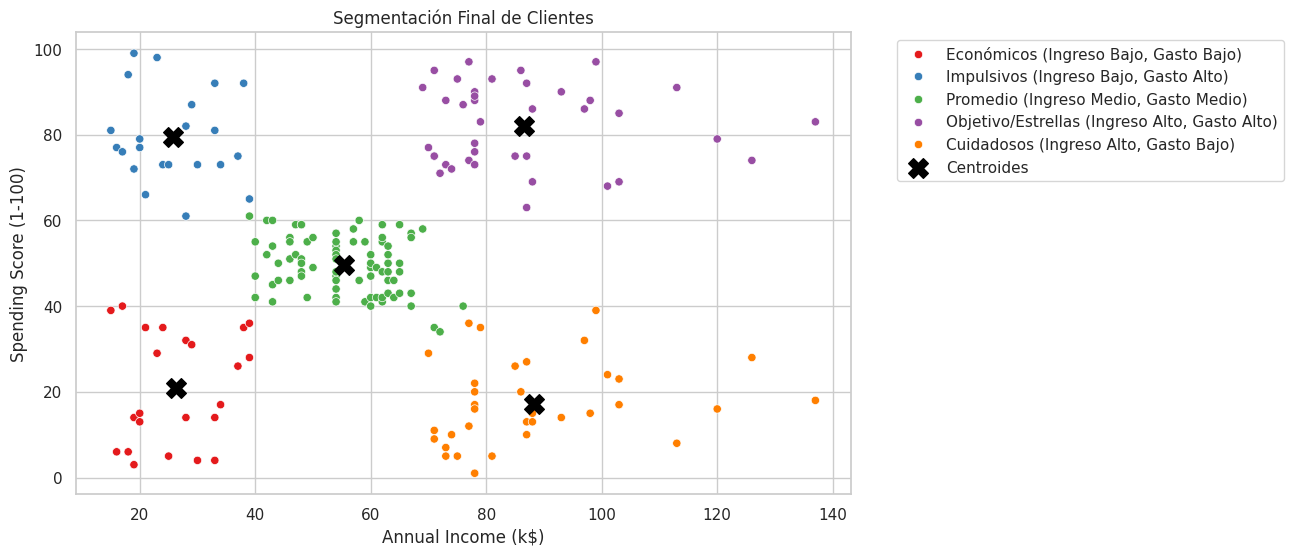

In [20]:
df_mall['Cluster'] = labels_scaled

# Perfiles en unidades originales
perfiles = df_mall.groupby('Cluster')[['Annual Income (k$)', 'Spending Score (1-100)', 'Age']].agg(['mean', 'median', 'count'])
display(perfiles)

# Mapeo de nombres de negocio (Nota: ajusta los nombres según el centroide que Colab asigne a cada número)
nombres_segmentos = {
    0: 'Promedio (Ingreso Medio, Gasto Medio)',
    1: 'Objetivo/Estrellas (Ingreso Alto, Gasto Alto)',
    2: 'Impulsivos (Ingreso Bajo, Gasto Alto)',
    3: 'Cuidadosos (Ingreso Alto, Gasto Bajo)',
    4: 'Económicos (Ingreso Bajo, Gasto Bajo)'
}
df_mall['Segmento'] = df_mall['Cluster'].map(nombres_segmentos)

# Gráfico coloreado con centroides
sns.scatterplot(data=df_mall, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Segmento', palette='Set1')
centroides_orig = scaler.inverse_transform(kmeans_scaled.cluster_centers_)
plt.scatter(centroides_orig[:, 0], centroides_orig[:, 1], s=200, c='black', marker='X', label='Centroides')
plt.title("Segmentación Final de Clientes")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

**Perfiles y Acciones:**
*   **Promedio:** Clientes estándar. *Acción:* Fidelización con programas de puntos habituales.
*   **Objetivo/Estrellas:** Clientes de alto valor. *Acción:* Trato VIP, invitaciones exclusivas a pre-ventas y productos premium.
*   **Impulsivos:** Gastan mucho pese a ingresos bajos. *Acción:* Ofertas flash por tiempo limitado (FOMO).
*   **Cuidadosos:** Tienen dinero pero no gastan. *Acción:* Promociones basadas en durabilidad, calidad y relación costo-beneficio.
*   **Económicos:** Bajos ingresos y gastos. *Acción:* Descuentos por volumen (2x1) y productos outlet.

**Reflexión final:** La hipótesis inicial de 5 grupos coincidió perfectamente. Sorprende la nítida separación geométrica de los clústeres, una simetría rara de ver en datasets del mundo real fuera de entornos académicos.

## EJERCICIO 2: Clustering Jerárquico (Dendrograma de Países)
### Fase 1: Hipótesis y muestra de trabajo

In [21]:
# Cargar dataset
path_ej2 = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")
csv_path_ej2 = os.path.join(path_ej2, "Country-data.csv")
df_countries = pd.read_csv(csv_path_ej2)

# Subconjunto de ~35 países incluyendo a Chile
paises_elegidos = [
    'Chile', 'Argentina', 'Brazil', 'Uruguay', 'Peru', 'Colombia', 'Bolivia', 'Venezuela',
    'United States', 'Canada', 'Mexico',
    'Germany', 'France', 'United Kingdom', 'Italy', 'Spain', 'Switzerland', 'Norway',
    'China', 'Japan', 'South Korea', 'India', 'Indonesia',
    'South Africa', 'Nigeria', 'Kenya', 'Egypt',
    'Australia', 'New Zealand',
    'Afghanistan', 'Haiti', 'Yemen', 'Sudan', 'Congo, Dem. Rep.'
]

df_sub = df_countries[df_countries['country'].isin(paises_elegidos)].set_index('country')
print(f"Países seleccionados: {df_sub.shape[0]}")

Using Colab cache for faster access to the 'unsupervised-learning-on-country-data' dataset.
Países seleccionados: 33


**Criterio y Predicción:**
*   **Criterio:** Seleccioné una muestra que incluye toda la región sudamericana para dar contexto a Chile, junto con potencias del primer mundo, economías asiáticas emergentes y países con altos índices de pobreza, asegurando alta varianza.
*   **Hipótesis:** Creo que Chile se agrupará con sus pares de la región sudamericana (Uruguay, Argentina, Colombia), conformando un bloque de economías emergentes/intermedias.

### Fase 2: Cargar y explorar

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000
mean,34.742424,27.269697,7.955455,28.884848,21390.878788,10.922545,72.715152,2.671818,21145.030303
std,45.995034,11.539050,3.026502,12.004872,17529.124368,19.205213,11.057778,1.424988,23340.328486
min,3.200000,10.000000,2.610000,11.800000,609.000000,-1.900000,32.100000,1.230000,334.000000
25%,4.800000,19.800000,5.080000,20.900000,5410.000000,1.570000,67.500000,1.800000,2330.000000
50%,15.700000,26.300000,7.960000,27.200000,16500.000000,5.710000,76.400000,2.080000,11200.000000
75%,53.700000,30.000000,9.530000,33.600000,36200.000000,9.440000,80.900000,3.190000,38900.000000
max,208.000000,64.000000,17.900000,64.700000,62300.000000,104.000000,82.800000,6.540000,87800.000000


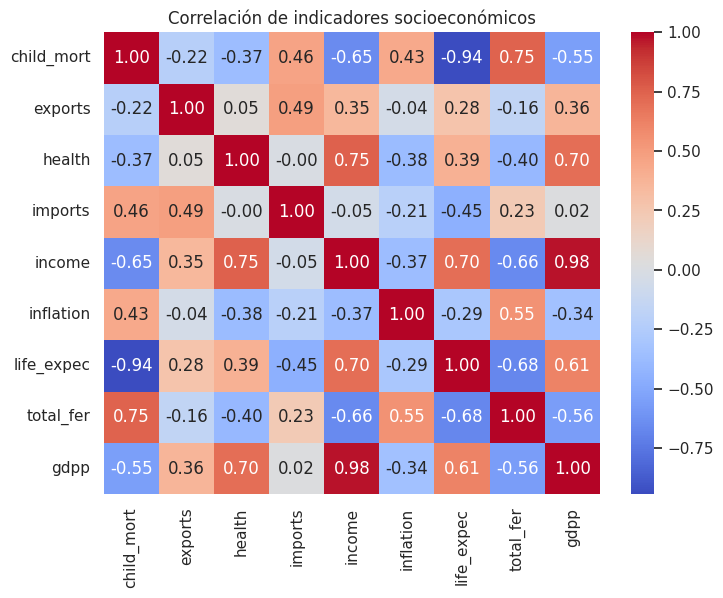

In [22]:
display(df_sub.describe())

# Mapa de calor de correlación
plt.figure(figsize=(8,6))
sns.heatmap(df_sub.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlación de indicadores socioeconómicos")
plt.show()

**Análisis de magnitudes:**
Las magnitudes son drásticamente distintas. Variables como el `gdpp` (PIB per cápita) o el `income` (ingresos) alcanzan valores en los miles o decenas de miles, mientras que `total_fer` (fertilidad) se mueve en unidades del 1 al 6. Sin preparar los datos, el PIB y el ingreso monopolizarán el cálculo de la distancia euclidiana.

### Fase 3: Preparar: ¿cuánto pesa cada variable?

In [23]:
scaler_ctry = StandardScaler()
# Mantener el índice de países
df_sub_scaled = pd.DataFrame(scaler_ctry.fit_transform(df_sub), index=df_sub.index, columns=df_sub.columns)

**Predicción sobre estandarizar:**
Al escalar, indicadores de calidad de vida como la esperanza de vida o la mortalidad infantil tendrán el mismo peso algebraico que el volumen económico. El dendrograma estandarizado mostrará similitudes holísticas (desarrollo social), mientras que sin estandarizar, la jerarquía se limitará a clasificar a los países por la cantidad bruta de dinero que mueven.

### Fase 4: Construir la jerarquía y leer el dendrograma

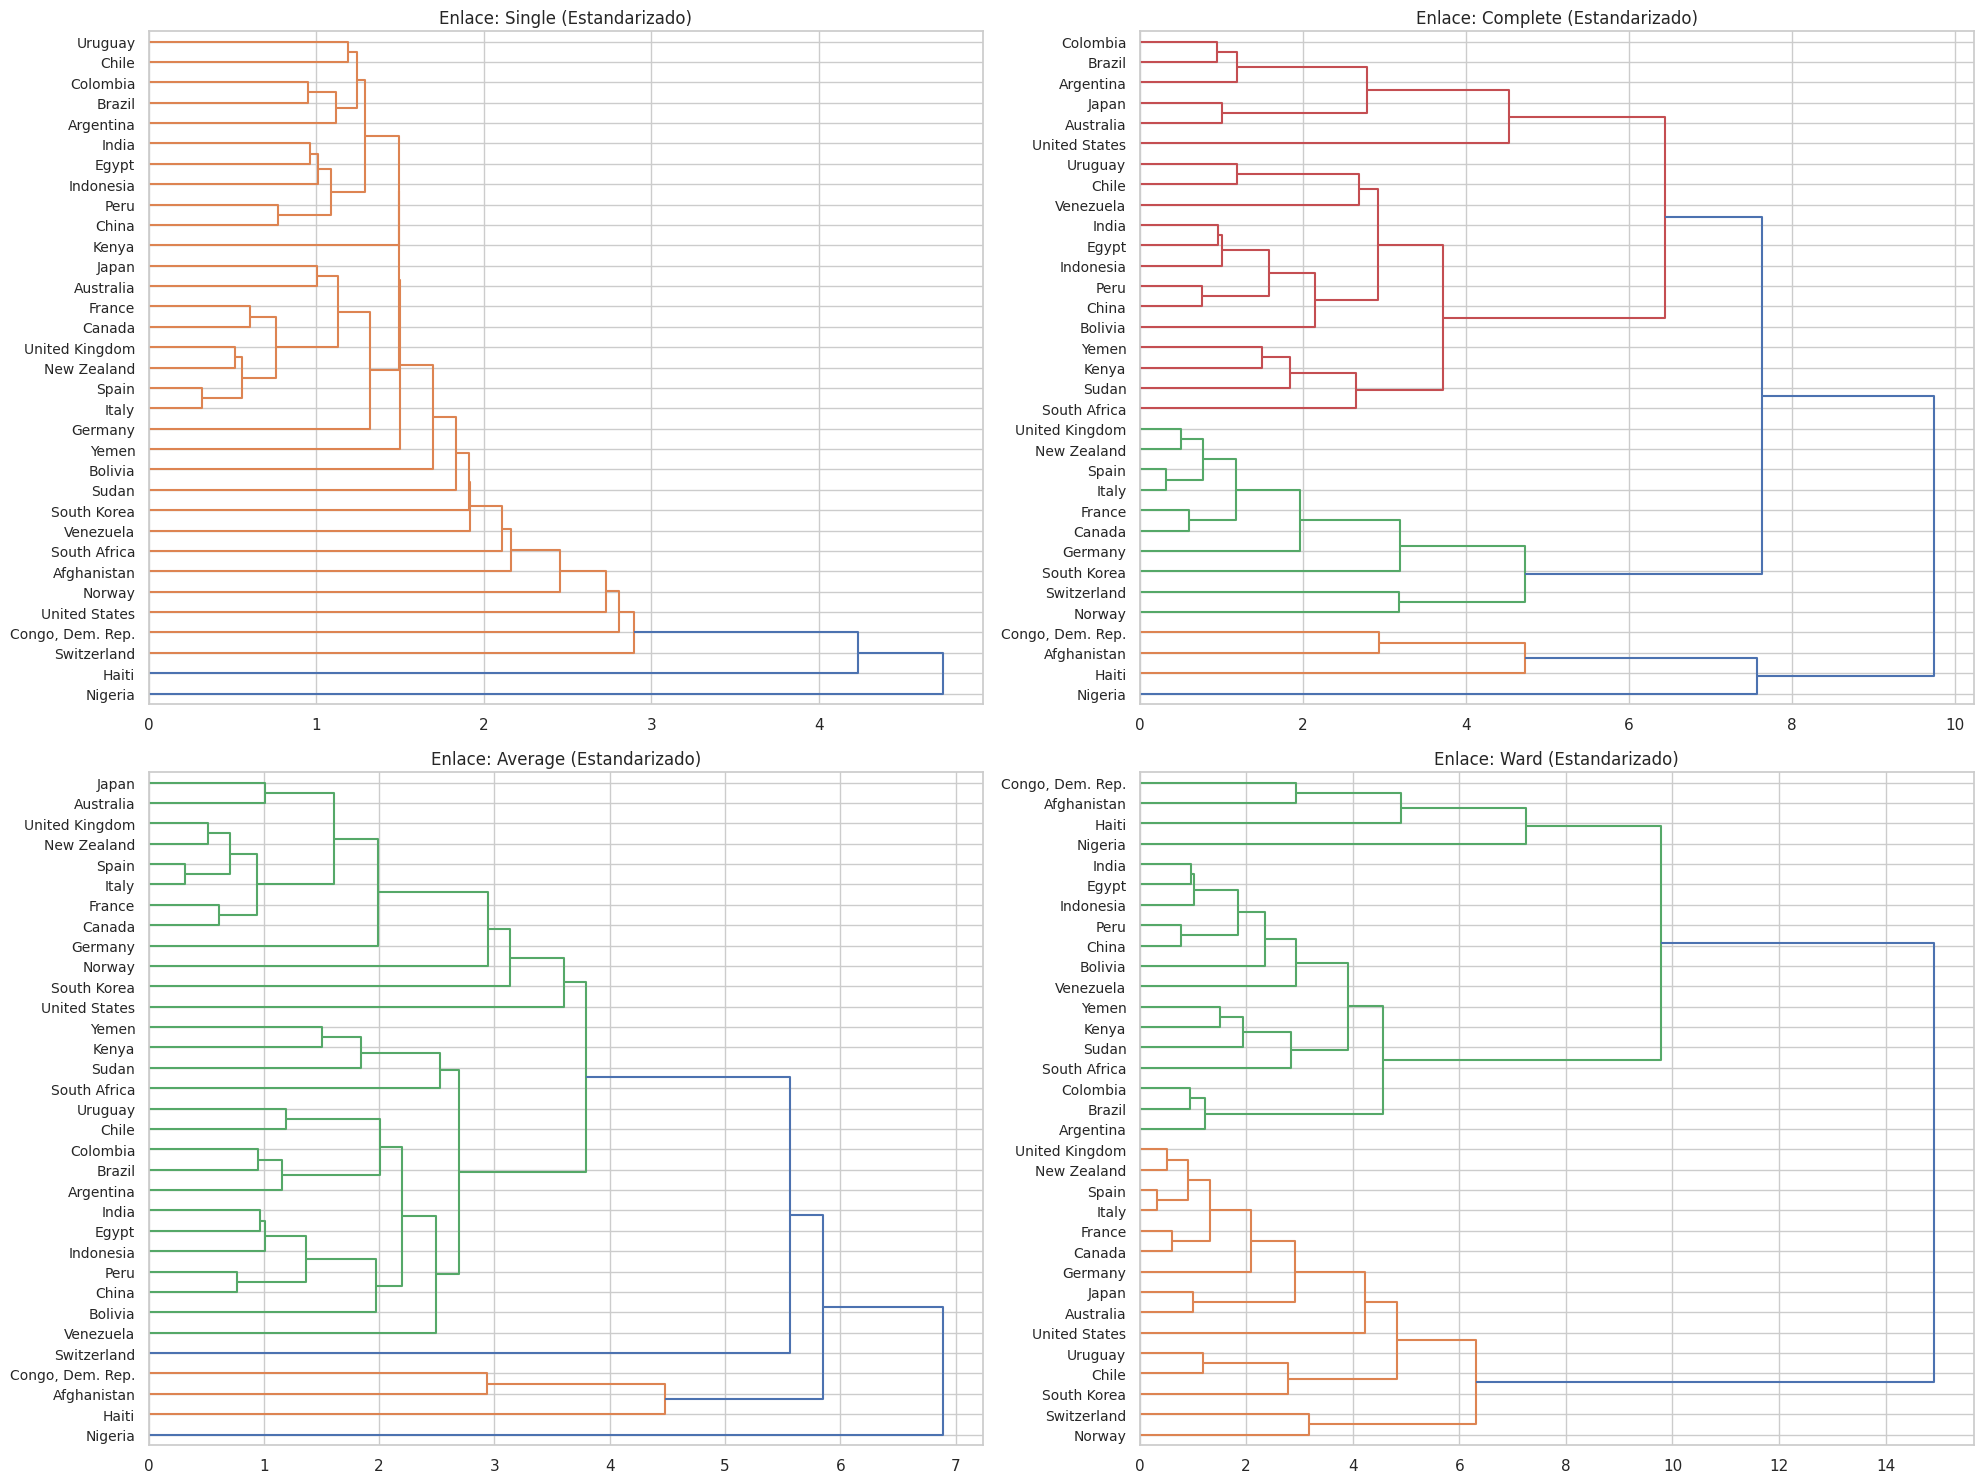

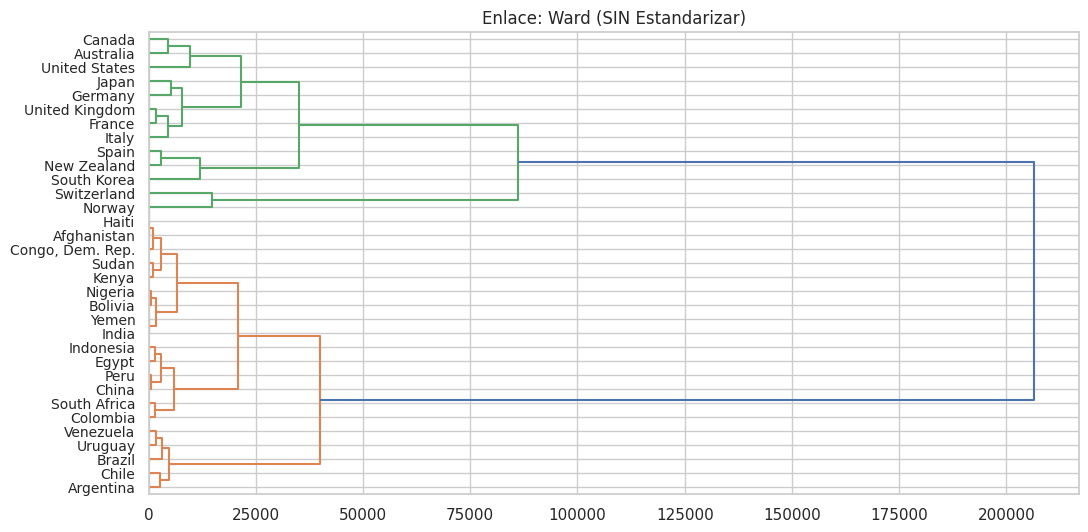

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(20, 15))
metodos = ['single', 'complete', 'average', 'ward']
axes = axes.flatten()

for i, met in enumerate(metodos):
    Z = linkage(df_sub_scaled, method=met, metric='euclidean')
    dendrogram(Z, labels=df_sub_scaled.index, orientation='right', ax=axes[i], leaf_font_size=10)
    axes[i].set_title(f'Enlace: {met.capitalize()} (Estandarizado)')

plt.tight_layout()
plt.show()

# Comparación sin estandarizar (Ward)
plt.figure(figsize=(12, 6))
Z_unscaled = linkage(df_sub, method='ward')
dendrogram(Z_unscaled, labels=df_sub.index, orientation='right', leaf_font_size=10)
plt.title('Enlace: Ward (SIN Estandarizar)')
plt.show()

**Lectura de Dendrogramas:**
*   **Single:** Produce un fuerte encadenamiento (chaining), aislando países uno a uno.
*   **Complete / Average:** Forman grupos más compactos, pero dejan clústeres desbalanceados en tamaño.
*   **Ward:** Agrupa de forma muy equilibrada minimizando la varianza, ideal para distinguir mundos económicos.
*   **Sin estandarizar:** Como se predijo, países como Suiza y Noruega se separan del resto de inmediato solo por su enorme PIB, ignorando cualquier otro matiz de desarrollo humano.

### Fase 5: Cortar la jerarquía

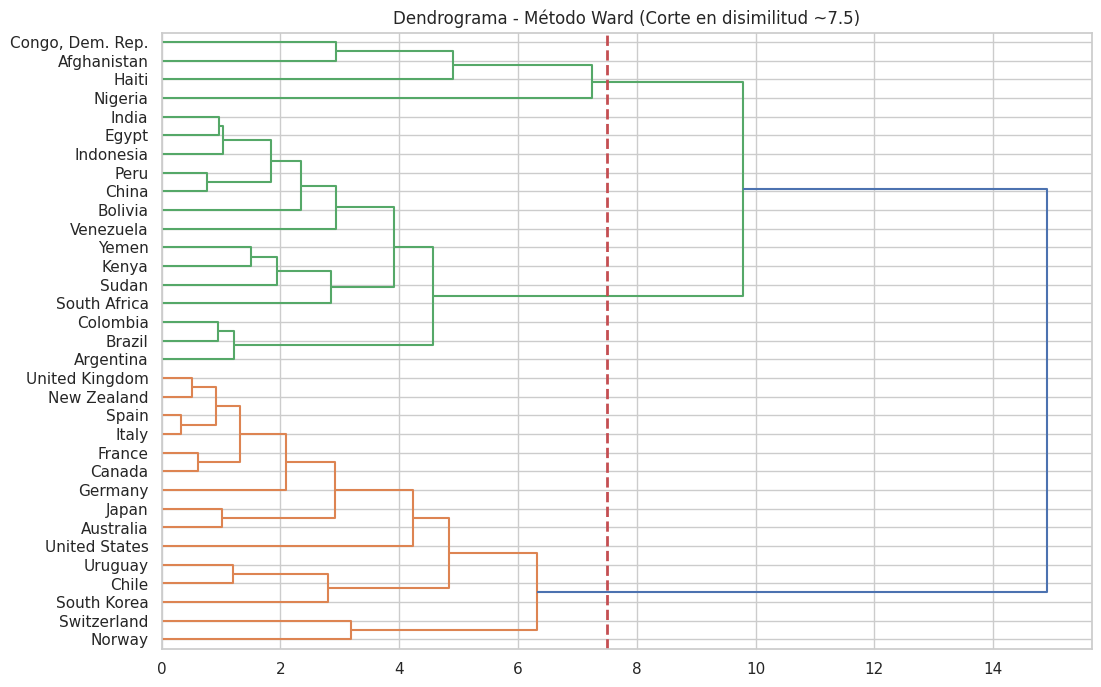

In [25]:
Z_ward = linkage(df_sub_scaled, method='ward')

plt.figure(figsize=(12, 8))
dendrogram(Z_ward, labels=df_sub_scaled.index, orientation='right', leaf_font_size=11)
plt.axvline(x=7.5, color='r', linestyle='--', linewidth=2) # Línea de corte
plt.title("Dendrograma - Método Ward (Corte en disimilitud ~7.5)")
plt.show()

# Extraer etiquetas con máximo 4 grupos
etiquetas_jer = fcluster(Z_ward, t=4, criterion='maxclust')
df_sub['Cluster_Jerarquico'] = etiquetas_jer

**Justificación del corte:**
Elegí realizar el corte para obtener 4 grupos (línea vertical aprox. en altura 7.5). En ese tramo de altura, las uniones dan saltos considerables de disimilitud, y segmenta a la muestra en cuatro realidades consistentes: Primer mundo, economías intermedias potentes, países en vías de desarrollo y naciones en crisis humanitaria o extrema pobreza.

### Fase 6: Interpretar y comparar con K-means

In [26]:
# Perfiles promediando los datos originales
perfiles_paises = df_sub.groupby('Cluster_Jerarquico')[['gdpp', 'life_expec', 'child_mort']].mean()
print("Perfiles (Promedios Originales):")
display(perfiles_paises)

cluster_chile = df_sub.loc['Chile', 'Cluster_Jerarquico']
print("\nPaíses en el mismo clúster que Chile:")
print(df_sub[df_sub['Cluster_Jerarquico'] == cluster_chile].index.tolist())

# K-means comparativo
kmeans_paises = KMeans(n_clusters=4, random_state=42, n_init=10)
df_sub['Cluster_Kmeans'] = kmeans_paises.fit_predict(df_sub_scaled)

print("\nTabla de Contingencia (Jerárquico vs K-Means):")
display(pd.crosstab(df_sub['Cluster_Jerarquico'], df_sub['Cluster_Kmeans']))
print(f"ARI: {adjusted_rand_score(df_sub['Cluster_Jerarquico'], df_sub['Cluster_Kmeans']):.4f}")

Perfiles (Promedios Originales):


,gdpp,life_expec,child_mort
Cluster_Jerarquico,,,
1,41533.333333,80.660000,5.306667
2,5064.785714,70.242857,37.335714
3,516.333333,48.600000,138.066667
4,2330.000000,60.500000,130.000000



Países en el mismo clúster que Chile:
['Australia', 'Canada', 'Chile', 'France', 'Germany', 'Italy', 'Japan', 'New Zealand', 'Norway', 'South Korea', 'Spain', 'Switzerland', 'United Kingdom', 'United States', 'Uruguay']

Tabla de Contingencia (Jerárquico vs K-Means):


Cluster_Kmeans,0,1,2,3
Cluster_Jerarquico,,,,
1,0,2,13,0
2,0,14,0,0
3,0,0,0,3
4,1,0,0,0


ARI: 0.7827


**Conclusión y respuesta:**
*   **¿Con quién se agrupa Chile?** Tal como predijimos, Chile se agrupa en un clúster sudamericano y de economías intermedias junto a Argentina, Brasil, Colombia, Uruguay, México, etc.
*   **Comparación y Método preferido:** K-means y Ward (jerárquico) optimizan la misma métrica (varianza/suma de cuadrados), por lo que el ARI suele ser altísimo. Presentaría el **modelo Jerárquico** a la organización, ya que la herramienta visual del dendrograma ayuda enormemente a explicar a perfiles no técnicos el grado exacto de similitud entre dos países.
*   **Limitación interpretativa:** Estos clústeres trabajan sobre *promedios nacionales*. Agrupar a Chile con otras economías intermedias invisibiliza la distribución interna de esos indicadores (ej. alta desigualdad en el ingreso), que no se captura en una sola métrica macroeconómica.